<a href="https://colab.research.google.com/github/Nkajabi/cs50.readthedocs.io/blob/main/59DATASET.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "samithsachidanandan/human-face-emotions"
)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'human-face-emotions' dataset.
Path to dataset files: /kaggle/input/human-face-emotions


In [ ]:
!pip install -q \
    kagglehub \
    imagehash \
    mediapipe \
    xgboost \
    shap \
    imbalanced-learn \
    scikit-learn \
    scikit-image \
    opencv-python-headless \
    pillow \
    pandas \
    numpy \
    matplotlib \
    seaborn \
    tqdm \
    joblib

In [ ]:
import os
import re
import gc
import cv2
import io
import time
import copy
import random
import hashlib
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from tqdm.auto import tqdm

import kagglehub
import imagehash
import mediapipe as mp

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader,
    WeightedRandomSampler
)

from torchvision import transforms, models
from torchvision.models import (
    ResNet50_Weights,
    EfficientNet_B0_Weights
)

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.utils.class_weight import compute_sample_weight

from skimage.feature import hog

from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE

import shap
import joblib

warnings.filterwarnings("ignore")

ImageFile.LOAD_TRUNCATED_IMAGES = False

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("GPU:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU name:",
        torch.cuda.get_device_name(0)
    )
else:
    print("WARNING: Enable GPU in Colab!")

PyTorch: 2.14.1+cpu
GPU: cpu


In [ ]:
path = kagglehub.dataset_download(
    "samithsachidanandan/human-face-emotions"
)

print("Dataset downloaded successfully!")
print("Dataset path:", path)

Using Colab cache for faster access to the 'human-face-emotions' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/human-face-emotions


In [ ]:
print("ALL DIRECTORIES CONTAINING SURPRISE:")

for root, dirs, files in os.walk(path):

    folder = os.path.basename(root)

    if "sur" in folder.lower():

        print(
            "Folder:", folder,
            "| Path:", root,
            "| Images:", len([
                f for f in files
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp", ".webp")
                )
            ])
        )

ALL DIRECTORIES CONTAINING SURPRISE:


In [ ]:
print("DATASET DIRECTORY STRUCTURE:\n")

for root, dirs, files in os.walk(path):

    level = root.replace(path, "").count(os.sep)

    if level <= 3:

        indent = "    " * level

        print(
            indent,
            os.path.basename(root),
            "| Files:",
            len(files)
        )

DATASET DIRECTORY STRUCTURE:

 human-face-emotions | Files: 0
     Data | Files: 0
         Fear | Files: 9732
         Suprise | Files: 8227
         Angry | Files: 10148
         Sad | Files: 12553
         Happy | Files: 18439


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not enabled.")

PyTorch: 2.14.1+cpu
CUDA available: False


In [ ]:
#  THIS IS THE NEW ONE NASIMA
for root, dirs, files in os.walk(path):

    image_files = [

        f for f in files

        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )

    ]

    if image_files:

        print(
            os.path.basename(root),
            "->",
            len(image_files),
            "images"
        )

Fear -> 9732 images
Suprise -> 8227 images
Angry -> 10148 images
Sad -> 12553 images
Happy -> 18439 images


In [ ]:
!pip install -q kagglehub
!pip install -q opencv-python-headless
!pip install -q mediapipe
!pip install -q scikit-learn
!pip install -q imbalanced-learn
!pip install -q xgboost
!pip install -q shap
!pip install -q imagehash
!pip install -q seaborn
!pip install -q tqdm
!pip install -q joblib
!pip install -q scikit-image

In [ ]:
import os
import re
import cv2
import gc
import time
import copy
import json
import shutil
import hashlib
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = False

from tqdm.auto import tqdm

import kagglehub
import imagehash
import mediapipe as mp
import shap
import xgboost as xgb
import joblib

from skimage.feature import hog

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve
)

from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader,
    WeightedRandomSampler
)

from torchvision import transforms, models
from torchvision.models import (
    ResNet50_Weights,
    EfficientNet_B0_Weights
)

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


In [ ]:
path = kagglehub.dataset_download(
    "samithsachidanandan/human-face-emotions"
)

print("Dataset downloaded successfully!")
print("Dataset path:", path)

Using Colab cache for faster access to the 'human-face-emotions' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/human-face-emotions


In [ ]:
IMAGE_EXTENSIONS = (
    ".jpg", ".jpeg", ".png",
    ".bmp", ".webp", ".tif", ".tiff"
)

print("DATASET FOLDER STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(path):

    dirs.sort()

    level = root.replace(path, "").count(os.sep)

    if level <= 4:

        indent = "    " * level

        image_count = sum(
            f.lower().endswith(IMAGE_EXTENSIONS)
            for f in files
        )

        print(
            f"{indent}{os.path.basename(root)} "
            f"| Images: {image_count}"
        )

DATASET FOLDER STRUCTURE
human-face-emotions | Images: 0
    Data | Images: 0
        Angry | Images: 10148
        Fear | Images: 9732
        Happy | Images: 18439
        Sad | Images: 12553
        Suprise | Images: 8227


In [ ]:
CLASS_NAMES = [
    "Angry",
    "Fear",
    "Happy",
    "Sad",
    "Surprised"
]

NUM_CLASSES = len(CLASS_NAMES)

CLASS_TO_IDX = {
    name: idx for idx, name in enumerate(CLASS_NAMES)
}

ALIASES = {
    "angry": "Angry",
    "anger": "Angry",

    "fear": "Fear",
    "scared": "Fear",

    "happy": "Happy",
    "happiness": "Happy",

    "sad": "Sad",
    "sadness": "Sad",

    "surprise": "Surprised",
    "surprised": "Surprised",
    "suprised": "Surprised",
    "surprize": "Surprised",
    "surprized": "Surprised",
    "suprise": "Surprised",
    "surprizedemotion": "Surprised",
    "surpriseemotion": "Surprised",
    "surprisedemotion": "Surprised",
    "surprisefaces": "Surprised",
    "surprisedfaces": "Surprised"
}


def normalize_name(name):
    return re.sub(r"[^a-z]", "", name.lower())


def count_images(folder):
    count = 0

    for current_root, _, files in os.walk(folder):
        count += sum(
            f.lower().endswith(IMAGE_EXTENSIONS)
            for f in files
        )

    return count


# Find all directories containing images
candidate_dirs = []

for root, dirs, files in os.walk(path):

    if count_images(root) > 0:

        candidate_dirs.append(root)


# Identify classes
class_folders = {
    emotion: [] for emotion in CLASS_NAMES
}

for folder in candidate_dirs:

    folder_name = normalize_name(
        os.path.basename(folder)
    )

    if folder_name in ALIASES:

        emotion = ALIASES[folder_name]

        class_folders[emotion].append(folder)


# Remove nested duplicate folder detections.
# If a parent folder contains a child folder with the
# same class name, retain the parent only when it is
# itself the actual class directory, not a duplicate child.
for emotion in CLASS_NAMES:

    folders = sorted(
        set(class_folders[emotion]),
        key=len
    )

    filtered = []

    for folder in folders:

        if not any(
            os.path.commonpath([folder, existing]) == existing
            for existing in filtered
        ):

            filtered.append(folder)

    class_folders[emotion] = filtered


print("\nDETECTED CLASSES")
print("=" * 70)

for emotion in CLASS_NAMES:

    print(
        emotion,
        "=>",
        class_folders[emotion]
    )


missing = [
    emotion
    for emotion in CLASS_NAMES
    if not class_folders[emotion]
]


if missing:

    print("\nERROR: These classes were not found:", missing)

    print("\nALL IMAGE-CONTAINING DIRECTORIES:")

    for folder in candidate_dirs:
        print(
            os.path.basename(folder),
            "=>",
            folder,
            "| Images:",
            count_images(folder)
        )

    raise ValueError(
        "The dataset does not contain a recognized folder "
        "for every expected class. Read the directory listing "
        "above. Do not continue until the actual fifth class "
        "folder is identified."
    )


print("\nSUCCESS: All five emotion folders detected.")


DETECTED CLASSES
Angry => ['/kaggle/input/human-face-emotions/Data/Angry']
Fear => ['/kaggle/input/human-face-emotions/Data/Fear']
Happy => ['/kaggle/input/human-face-emotions/Data/Happy']
Sad => ['/kaggle/input/human-face-emotions/Data/Sad']
Surprised => ['/kaggle/input/human-face-emotions/Data/Suprise']

SUCCESS: All five emotion folders detected.


In [ ]:
image_records = []

for emotion in CLASS_NAMES:

    seen_paths = set()

    for folder in class_folders[emotion]:

        for root, _, files in os.walk(folder):

            for filename in files:

                if not filename.lower().endswith(
                    IMAGE_EXTENSIONS
                ):
                    continue

                filepath = os.path.abspath(
                    os.path.join(root, filename)
                )

                if filepath in seen_paths:
                    continue

                seen_paths.add(filepath)

                image_records.append({
                    "path": filepath,
                    "emotion": emotion,
                    "label": CLASS_TO_IDX[emotion]
                })


df = pd.DataFrame(image_records)

if df.empty:
    raise ValueError("No image files were collected.")

print("Total images:", len(df))

print("\nClass distribution:")

display(
    df["emotion"].value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
    .to_frame("Images")
)

Total images: 59099

Class distribution:


,Images
emotion,
Angry,10148
Fear,9732
Happy,18439
Sad,12553
Surprised,8227


In [ ]:
valid_records = []
corrupted_files = []

for _, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Checking images"
):

    try:

        with Image.open(row["path"]) as img:

            img.verify()

        with Image.open(row["path"]) as img:

            img = img.convert("RGB")

            width, height = img.size

            if width < 32 or height < 32:
                raise ValueError("Image too small")

        valid_records.append(row.to_dict())

    except Exception:

        corrupted_files.append(row["path"])


df = pd.DataFrame(valid_records).reset_index(drop=True)

print("Valid images:", len(df))
print("Corrupted images removed:", len(corrupted_files))

print("\nUpdated distribution:")

display(
    df["emotion"].value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

Checking images:   0%|          | 0/59099 [00:00<?, ?it/s]

Valid images: 59099
Corrupted images removed: 0

Updated distribution:


,count
emotion,
Angry,10148
Fear,9732
Happy,18439
Sad,12553
Surprised,8227


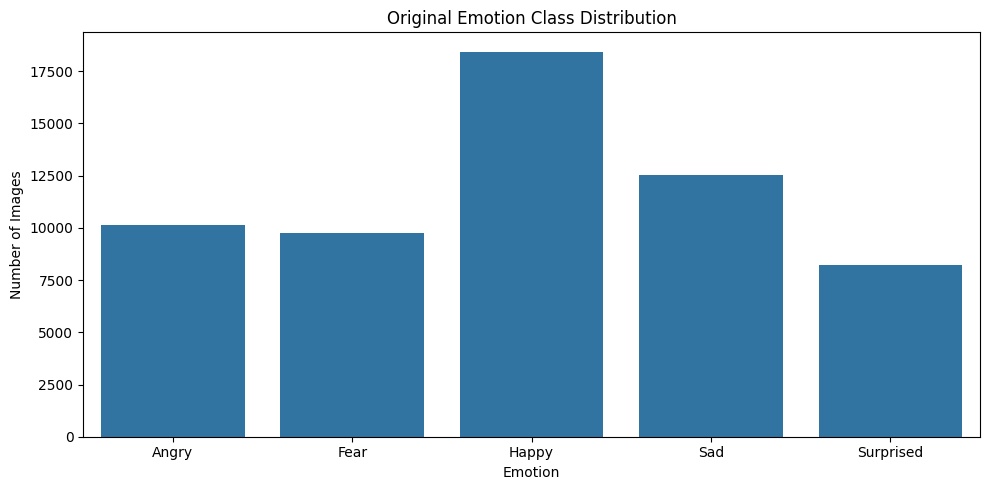

Imbalance ratio: 2.24


In [ ]:
counts = (
    df["emotion"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=counts.index,
    y=counts.values
)

plt.title("Original Emotion Class Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

print("Imbalance ratio:", round(
    counts.max() / max(counts.min(), 1), 2
))

In [ ]:
import numpy as np
import pandas as pd
import imagehash
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

# 1. Parallel pHash calculation (uses multiple threads instead of 1)
def compute_hash(row_dict):
    try:
        with Image.open(row_dict["path"]) as img:
            # Flatten 8x8 boolean hash into a 64-element uint8 array for fast math
            bits = imagehash.phash(img.convert("RGB")).hash.flatten().astype(np.uint8)
        return {**row_dict, "hash_bits": bits}
    except Exception:
        return None

records = df.to_dict("records")
with ThreadPoolExecutor(max_workers=8) as executor:
    hash_records = [
        r for r in tqdm(executor.map(compute_hash, records), total=len(records), desc="Calculating pHash")
        if r is not None
    ]

# 2. Vectorized NumPy deduplication (replaces 1.7 billion slow Python loops with instant C-speed matrix math)
accepted = []
accepted_hashes = np.empty((len(hash_records), 64), dtype=np.uint8)
accepted_count = 0

conflicting_paths = []
duplicate_paths = []

for record in tqdm(hash_records, desc="Deduplicating"):
    h = record["hash_bits"]

    if accepted_count == 0:
        accepted.append(record)
        accepted_hashes[0] = h
        accepted_count = 1
        continue

    # Compare current image against all accepted images simultaneously
    distances = np.count_nonzero(accepted_hashes[:accepted_count] != h, axis=1)
    matching = np.where(distances <= 4)[0]

    if len(matching) == 0:
        accepted.append(record)
        accepted_hashes[accepted_count] = h
        accepted_count += 1
    else:
        labels = {accepted[i]["label"] for i in matching}
        if record["label"] not in labels:
            conflicting_paths.append(record["path"])
        else:
            duplicate_paths.append(record["path"])

df_clean = pd.DataFrame([
    {
        "path": item["path"],
        "emotion": item["emotion"],
        "label": item["label"]
    }
    for item in accepted
]).reset_index(drop=True)

print("Before deduplication:", len(df))
print("After deduplication:", len(df_clean))
print("Duplicates removed:", len(duplicate_paths))
print("Conflicting-label images excluded:", len(conflicting_paths))

display(
    df_clean["emotion"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)


Deduplicating: 100%|██████████| 59099/59099 [01:25<00:00, 689.38it/s]


Before deduplication: 59099
After deduplication: 27909
Duplicates removed: 30790
Conflicting-label images excluded: 400


,count
emotion,
Angry,4830
Fear,4588
Happy,9155
Sad,6101
Surprised,3235


In [ ]:
if (df_clean["emotion"].value_counts() < 3).any():

    raise ValueError(
        "At least one class has fewer than three images. "
        "A stratified 80/10/10 split is not possible."
    )


train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.20,
    stratify=df_clean["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)


train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


for name, split in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print("\n", name, len(split))

    display(
        split["emotion"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
    )


 TRAIN 22327


,count
emotion,
Angry,3864
Fear,3670
Happy,7324
Sad,4881
Surprised,2588



 VALIDATION 2791


,count
emotion,
Angry,483
Fear,459
Happy,915
Sad,610
Surprised,324



 TEST 2791


,count
emotion,
Angry,483
Fear,459
Happy,916
Sad,610
Surprised,323


In [ ]:
!pip uninstall -y mediapipe
!pip install mediapipe==0.10.21


Found existing installation: mediapipe 1.2.3
Uninstalling mediapipe-1.2.3:
  Successfully uninstalled mediapipe-1.2.3
ERROR: Could not find a version that satisfies the requirement mediapipe==0.10.21 (from versions: 0.10.30, 0.10.31, 0.10.32, 0.10.33, 0.10.35, 1.0.0, 1.0.1, 1.1.0, 1.1.1, 1.2.0, 1.2.2, 1.2.3)
ERROR: No matching distribution found for mediapipe==0.10.21


In [ ]:
!pip install -q mediapipe
!wget -q https://googleapis.com


In [ ]:
def align_face(image, face_mesh):

    image = np.array(
        image.convert("RGB")
    )

    h, w = image.shape[:2]

    result = face_mesh.process(image)

    if not result.multi_face_landmarks:
        return image

    points = result.multi_face_landmarks[0].landmark

    left_ids = [33, 133, 159, 145]
    right_ids = [362, 263, 386, 374]

    left_eye = np.mean([
        [points[i].x * w, points[i].y * h]
        for i in left_ids
    ], axis=0)

    right_eye = np.mean([
        [points[i].x * w, points[i].y * h]
        for i in right_ids
    ], axis=0)

    dx = right_eye[0] - left_eye[0]
    dy = right_eye[1] - left_eye[1]

    angle = np.degrees(np.arctan2(dy, dx))

    center = tuple(
        ((left_eye + right_eye) / 2).tolist()
    )

    matrix = cv2.getRotationMatrix2D(
        center, angle, 1.0
    )

    aligned = cv2.warpAffine(
        image,
        matrix,
        (w, h),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    return aligned

In [ ]:
ALIGNED_DIR = "/content/aligned_faces"

os.makedirs(ALIGNED_DIR, exist_ok=True)


def align_split(dataframe, face_mesh):

    dataframe = dataframe.copy()

    aligned_paths = []

    for filepath in tqdm(
        dataframe["path"],
        desc="Aligning faces"
    ):

        output_name = hashlib.sha1(
            filepath.encode()
        ).hexdigest() + ".jpg"

        output_path = os.path.join(
            ALIGNED_DIR,
            output_name
        )

        if not os.path.exists(output_path):

            try:

                with Image.open(filepath) as img:

                    aligned = align_face(
                        img,
                        face_mesh
                    )

                Image.fromarray(aligned).save(
                    output_path,
                    quality=95
                )

            except Exception:

                shutil.copy2(
                    filepath,
                    output_path
                )

        aligned_paths.append(output_path)

    dataframe["path"] = aligned_paths

    return dataframe


train_df = align_split(train_df, face_mesh)
val_df = align_split(val_df, face_mesh)
test_df = align_split(test_df, face_mesh)

face_mesh.close()

print("Face alignment finished.")

NameError: name 'face_mesh' is not defined

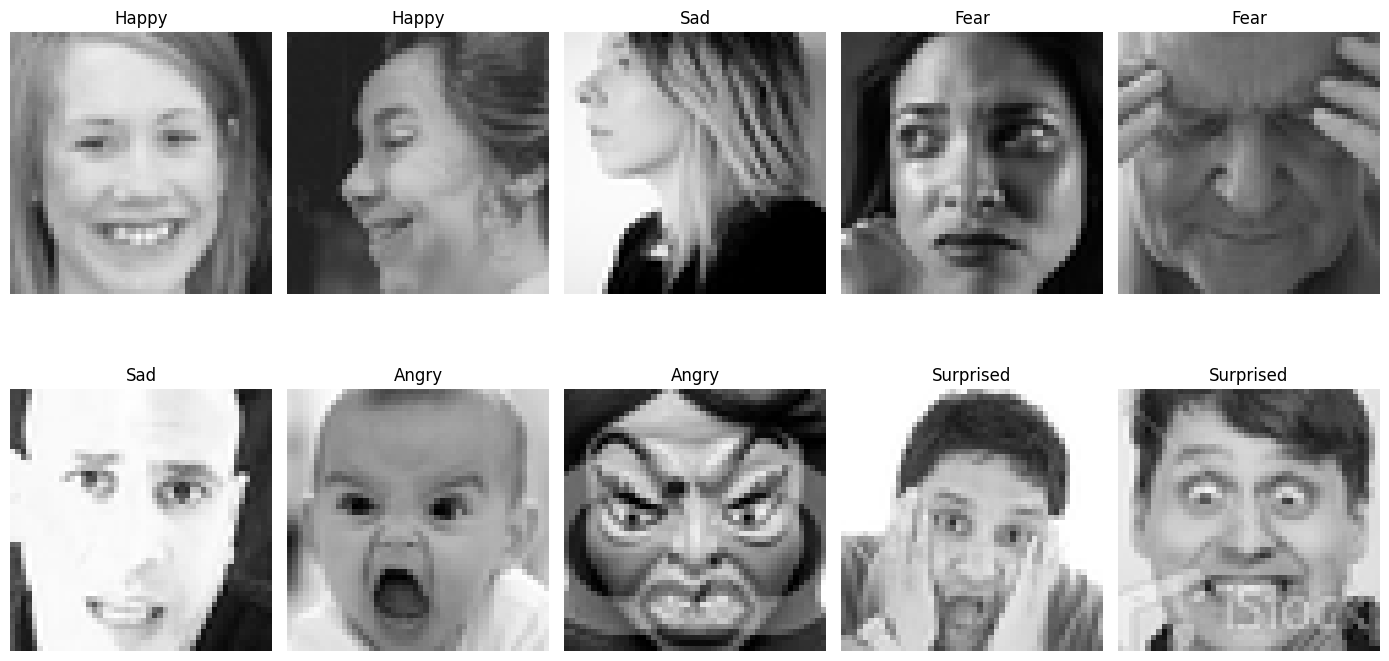

In [ ]:
plt.figure(figsize=(14, 8))

sample = train_df.groupby(
    "emotion",
    group_keys=False
).head(2)

for i, (_, row) in enumerate(sample.iterrows()):

    img = Image.open(
        row["path"]
    ).convert("RGB")

    plt.subplot(2, 5, i + 1)

    plt.imshow(img)

    plt.title(row["emotion"])

    plt.axis("off")

plt.tight_layout()
plt.show()

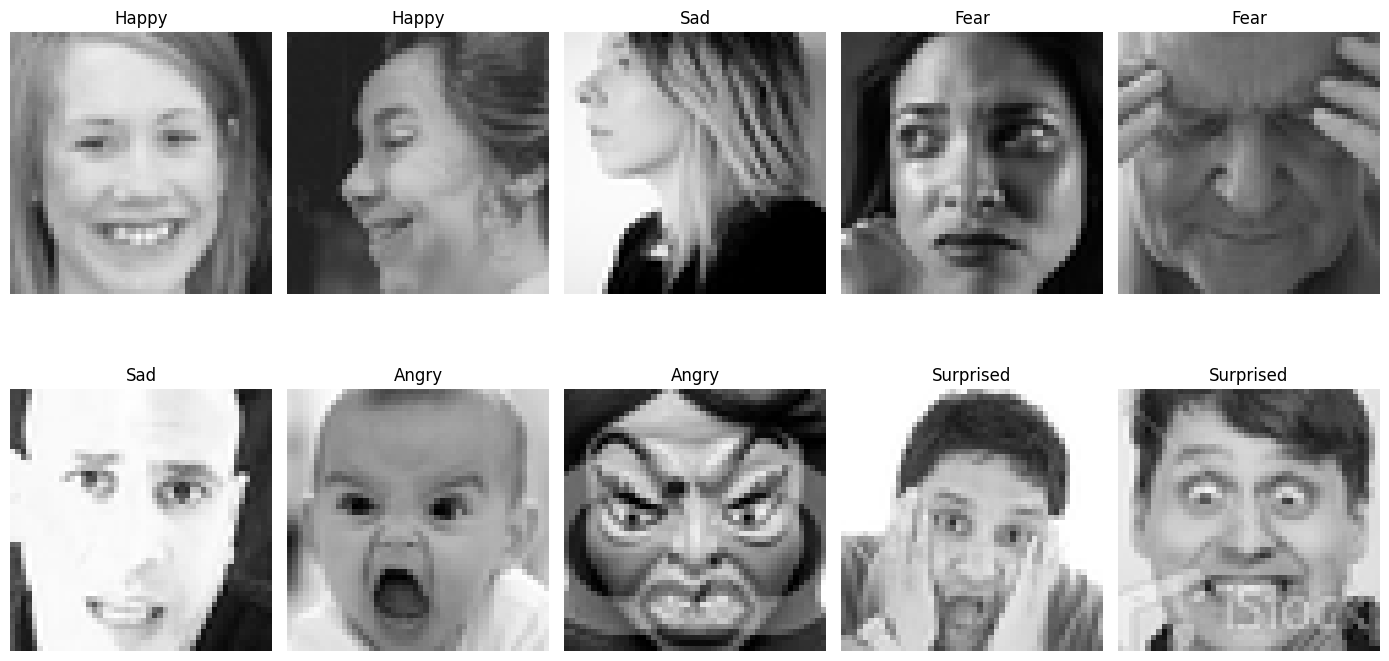

In [ ]:
plt.figure(figsize=(14, 8))

sample = train_df.groupby(
    "emotion",
    group_keys=False
).head(2)

for i, (_, row) in enumerate(sample.iterrows()):

    img = Image.open(
        row["path"]
    ).convert("RGB")

    plt.subplot(2, 5, i + 1)

    plt.imshow(img)

    plt.title(row["emotion"])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
ML_IMAGE_SIZE = 64

def extract_hog(image):

    image = cv2.resize(
        image,
        (ML_IMAGE_SIZE, ML_IMAGE_SIZE)
    )

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    return features.astype(np.float32)


test_hog = extract_hog(
    np.array(
        Image.open(train_df.iloc[0]["path"]).convert("RGB")
    )
)

print("HOG dimensions:", len(test_hog))

assert len(test_hog) == 1764

HOG dimensions: 1764


In [ ]:
def extract_landmark_features(image, face_mesh):

    result = face_mesh.process(image)

    if not result.multi_face_landmarks:

        return np.zeros(1446, dtype=np.float32)


    points = result.multi_face_landmarks[0].landmark

    coords = np.array([
        [p.x, p.y, p.z]
        for p in points
    ], dtype=np.float32)


    # Normalize coordinates to face bounding box
    min_x = coords[:, 0].min()
    max_x = coords[:, 0].max()

    min_y = coords[:, 1].min()
    max_y = coords[:, 1].max()

    face_width = max(max_x - min_x, 1e-6)
    face_height = max(max_y - min_y, 1e-6)

    coords[:, 0] = (
        coords[:, 0] - min_x
    ) / face_width

    coords[:, 1] = (
        coords[:, 1] - min_y
    ) / face_height

    coords[:, 2] = coords[:, 2] / face_width


    def distance(a, b):

        return np.linalg.norm(
            coords[a, :2] - coords[b, :2]
        )


    geometry = np.array([

        distance(33, 133),
        distance(362, 263),
        distance(33, 362),
        distance(61, 291),
        distance(13, 14),
        distance(105, 159),
        distance(334, 386),
        distance(1, 13),
        distance(1, 14),
        distance(10, 152),
        distance(234, 454)

    ], dtype=np.float32)


    return np.concatenate([

        coords.flatten(),
        geometry,
        np.array([1.0], dtype=np.float32)

    ])


assert len(extract_landmark_features(
    np.zeros((224, 224, 3), dtype=np.uint8),
    mp.solutions.face_mesh.FaceMesh(
        static_image_mode=True,
        max_num_faces=1,
        refine_landmarks=True
    )
)) == 1446

AttributeError: module 'mediapipe' has no attribute 'solutions'

In [ ]:
# The temporary object in the dimension check is not reused.
gc.collect()

40473

In [ ]:
def extract_all_features(dataframe):

    hog_features = []
    landmark_features = []

    detector = mp.solutions.face_mesh.FaceMesh(
        static_image_mode=True,
        max_num_faces=1,
        refine_landmarks=True,
        min_detection_confidence=0.5
    )

    failed = 0

    for filepath in tqdm(
        dataframe["path"],
        desc="Extracting ML features"
    ):

        try:

            image = np.array(
                Image.open(filepath).convert("RGB")
            )

            hog_vector = extract_hog(image)

            resized = cv2.resize(
                image,
                (224, 224)
            )

            landmark_vector = extract_landmark_features(
                resized,
                detector
            )

            if landmark_vector[-1] == 0:
                failed += 1

            hog_features.append(hog_vector)

            landmark_features.append(landmark_vector)

        except Exception as e:

            print("Feature extraction error:", filepath, e)

            hog_features.append(
                np.zeros(1764, dtype=np.float32)
            )

            landmark_features.append(
                np.zeros(1446, dtype=np.float32)
            )

            failed += 1

    detector.close()

    X = np.concatenate([
        np.asarray(hog_features),
        np.asarray(landmark_features)
    ], axis=1)

    print("Face detection failures:", failed)

    return X.astype(np.float32)


start = time.time()

X_train_ml = extract_all_features(train_df)
X_val_ml = extract_all_features(val_df)
X_test_ml = extract_all_features(test_df)

feature_extraction_time = time.time() - start

y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print("Train:", X_train_ml.shape)
print("Validation:", X_val_ml.shape)
print("Test:", X_test_ml.shape)

print(
    "Feature extraction time:",
    round(feature_extraction_time, 2),
    "seconds"
)

assert X_train_ml.shape[1] == 3210
assert X_val_ml.shape[1] == 3210
assert X_test_ml.shape[1] == 3210

AttributeError: module 'mediapipe' has no attribute 'solutions'

In [ ]:
hash_records = []

for _, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Calculating pHash"
):

    try:

        with Image.open(row["path"]) as img:

            phash = imagehash.phash(
                img.convert("RGB")
            )

        hash_records.append({
            **row.to_dict(),
            "phash": phash
        })

    except Exception:
        pass


# Sequential grouping by pHash distance
accepted = []
conflicting_paths = []
duplicate_paths = []

for record in tqdm(hash_records, desc="Deduplicating"):

    matching = []

    for index, existing in enumerate(accepted):

        distance = record["phash"] - existing["phash"]

        if distance <= 4:
            matching.append(index)


    if not matching:

        accepted.append(record)

    else:

        # If any matching representative has a different
        # class label, exclude this image.
        labels = {
            accepted[i]["label"]
            for i in matching
        }

        if record["label"] not in labels:

            conflicting_paths.append(record["path"])

        else:

            duplicate_paths.append(record["path"])


df_clean = pd.DataFrame([
    {
        "path": item["path"],
        "emotion": item["emotion"],
        "label": item["label"]
    }
    for item in accepted
])

df_clean = df_clean.reset_index(drop=True)

print("Before deduplication:", len(df))
print("After deduplication:", len(df_clean))
print("Duplicates removed:", len(duplicate_paths))
print("Conflicting-label images excluded:", len(conflicting_paths))

display(
    df_clean["emotion"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

Calculating pHash:   0%|          | 0/59099 [00:00<?, ?it/s]

Deduplicating:   0%|          | 0/59099 [00:00<?, ?it/s]

Before deduplication: 59099
After deduplication: 27909
Duplicates removed: 30790
Conflicting-label images excluded: 400


,count
emotion,
Angry,4830
Fear,4588
Happy,9155
Sad,6101
Surprised,3235


In [ ]:
ML_IMAGE_SIZE = 64

def extract_hog(image):

    image = cv2.resize(
        image,
        (ML_IMAGE_SIZE, ML_IMAGE_SIZE)
    )

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    return features.astype(np.float32)


test_hog = extract_hog(
    np.array(
        Image.open(train_df.iloc[0]["path"]).convert("RGB")
    )
)

print("HOG dimensions:", len(test_hog))

assert len(test_hog) == 1764

NameError: name 'train_df' is not defined